In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# =====================================================================
# Task 1: Load the Data
# =====================================================================
# Load the built-in "tips" dataset from Seaborn
df = sns.load_dataset("tips")


Encountered this error:
```
SSLCertVerificationError                  Traceback (most recent call last)
File /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/urllib/request.py:1344, in AbstractHTTPHandler.do_open(self, http_class, req, **http_conn_args)
   1343 try:
-> 1344     h.request(req.get_method(), req.selector, req.data, headers,
   1345               encode_chunked=req.has_header('Transfer-encoding'))
   1346 except OSError as err: # timeout error
```

Fix in MacOS terminal then Restart VS Code:

```
/Applications/Python\ 3.12/Install\ Certificates.command
```


In [2]:

# =====================================================================
# Task 2: Basic Data Analysis
# =====================================================================
print("--- 2.1 First Few Rows ---")
print(df.head(), "\n")

print("--- 2.2 Dataset Summary (Info & Description) ---")
print(df.info())
print("\nDescriptive Statistics:")
print(df.describe(include="all"), "\n")

print("--- Missing Values Check ---")
print(df.isnull().sum(), "\n")

# 2.3 Fill missing values (Note: Seaborn's 'tips' dataset has 0 missing values,
# but here is the logic requested by the task)
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype.name in ["category", "object"]:
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].mean())

print("--- 2.4 Categorical Value Counts ---")
for col in ["sex", "day", "time"]:
    print(f"\nCounts for '{col}':")
    print(df[col].value_counts())
print("\n" + "=" * 50 + "\n")

--- 2.1 First Few Rows ---
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4 

--- 2.2 Dataset Summary (Info & Description) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB
None

Descriptive Statistics:
        total_bill     

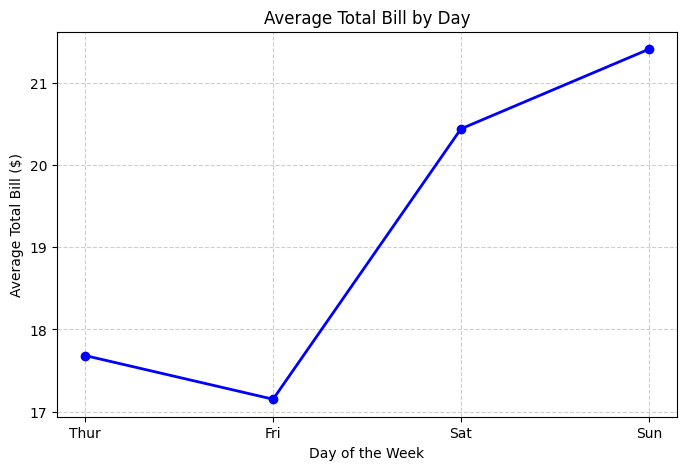

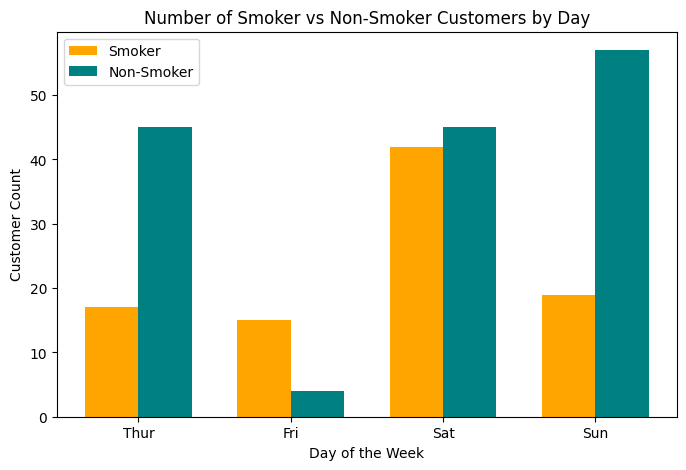

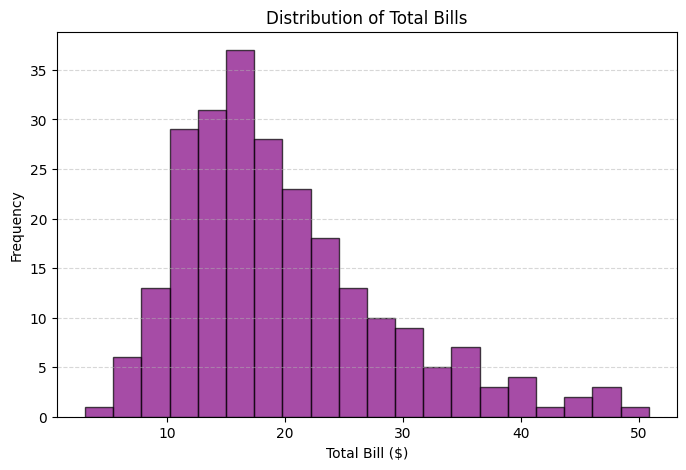

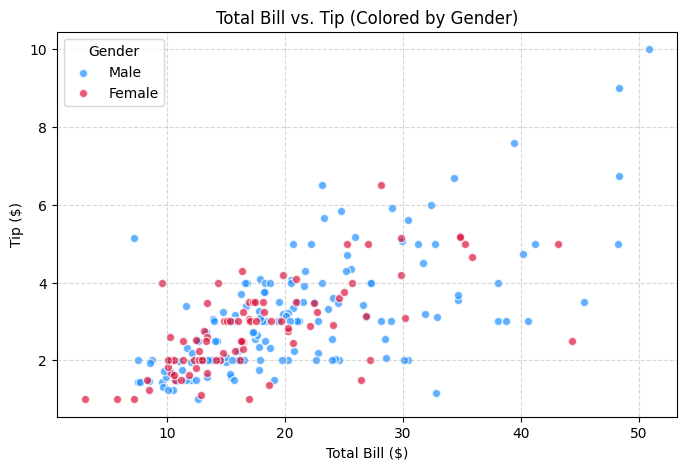

In [3]:
# =====================================================================
# Task 3: Matplotlib Visualization
# =====================================================================

# Standard chronological day order for the tips dataset
day_order = ["Thur", "Fri", "Sat", "Sun"]

# 3.1 Line Plot: Average total_bill by day
plt.figure(figsize=(8, 5))
avg_bill_by_day = df.groupby("day", observed=False)["total_bill"].mean().reindex(day_order)

plt.plot(
    avg_bill_by_day.index,
    avg_bill_by_day.values,
    marker="o",
    color="b",
    linestyle="-",
    linewidth=2,
)
plt.title("Average Total Bill by Day")
plt.xlabel("Day of the Week")
plt.ylabel("Average Total Bill ($)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 3.2 Bar Plot: Total number of smoker and non-smoker customers for each day
plt.figure(figsize=(8, 5))
# Create a pivot table to align smoker data with days
smoker_counts = (
    df.groupby(["day", "smoker"], observed=False)
    .size()
    .unstack()
    .reindex(day_order)
)

# Plotting grouped bars using matplotlib
x_indices = range(len(day_order))
bar_width = 0.35

plt.bar(
    [x - bar_width / 2 for x in x_indices],
    smoker_counts["Yes"],
    width=bar_width,
    label="Smoker",
    color="orange",
)
plt.bar(
    [x + bar_width / 2 for x in x_indices],
    smoker_counts["No"],
    width=bar_width,
    label="Non-Smoker",
    color="teal",
)

plt.xticks(x_indices, day_order)
plt.title("Number of Smoker vs Non-Smoker Customers by Day")
plt.xlabel("Day of the Week")
plt.ylabel("Customer Count")
plt.legend()
plt.show()

# 3.3 Histogram: Distribution of the total_bill column
plt.figure(figsize=(8, 5))
plt.hist(df["total_bill"], bins=20, color="purple", edgecolor="black", alpha=0.7)
plt.title("Distribution of Total Bills")
plt.xlabel("Total Bill ($)")
plt.ylabel("Frequency")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

# 3.4 Scatter Plot: Relationship between total_bill and tip (colored by sex)
plt.figure(figsize=(8, 5))
colors = {"Male": "dodgerblue", "Female": "crimson"}

for gender, group in df.groupby("sex", observed=False):
    plt.scatter(
        group["total_bill"],
        group["tip"],
        color=colors[gender],
        label=gender,
        alpha=0.7,
        edgecolors="w",
    )

plt.title("Total Bill vs. Tip (Colored by Gender)")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.legend(title="Gender")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()